# Loading libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from tqdm import tqdm
from scipy.integrate import solve_ivp


# Importing the data

In [2]:
df = pd.read_csv('Covid-Variant-Indonesia-GISAID.csv')
pd.set_option('display.max_rows', None)

# Define the date and variants

In [3]:
df['Date'] = pd.to_datetime(df['Date'])

variants = ['Alpha', 'Beta', 'Delta', 'Eta', 'Kappa', 'Omicron']
omicron_variants = ['Omicron']
delta_variants = ['Delta']
df_variant = df[df['Variant'].isin(variants)]

all_dates = pd.date_range(
    start=pd.Timestamp("2021-06-06"),
    end=pd.Timestamp("2023-01-01")
)

total = df['Count'].sum()
variant_total = df.groupby('Variant')['Count'].sum()
global_prop = variant_total/total
normalised_prop = variant_total/variant_total.max()

variant_time_series = pd.DataFrame(index=all_dates)

for variant in variants:
    variant_data = df_variant[df_variant['Variant'] == variant]
    variant_agg = variant_data.groupby('Date')['Count'].sum()
    variant_series = variant_agg.reindex(all_dates, fill_value=0)
    variant_time_series[variant] = variant_series

# Plotting weekly cases of Delta and Omicron variants

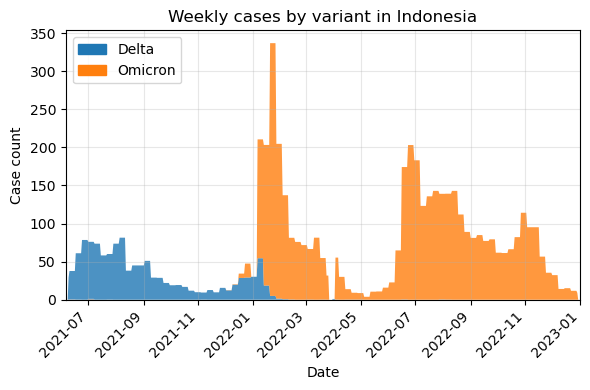

In [4]:
colors = {'Delta': 'tab:blue', 'Omicron': 'tab:orange'}

plt.figure(figsize=(6, 4))

filtered_dates_mask = (df_variant['Date'] >= all_dates.min()) & (df_variant['Date'] <= all_dates.max())
df_filtered = df_variant[filtered_dates_mask].copy()

daily_pivot = df_filtered.pivot_table(
    index='Date',
    columns='Variant',
    values='Count',
    aggfunc='sum'
).reindex(all_dates, fill_value=0)

smoothed_pivot = daily_pivot.rolling(window=7, center=True).mean().fillna(0)

plt.stackplot(
    smoothed_pivot.index,
    [smoothed_pivot[col] for col in smoothed_pivot.columns],
    labels=smoothed_pivot.columns,
    colors=[colors.get(col, 'gray') for col in smoothed_pivot.columns],
    alpha=0.8
)

handles = [
    mpatches.Patch(color=colors['Delta'], label='Delta'),
    mpatches.Patch(color=colors['Omicron'], label='Omicron')
]
plt.legend(handles=handles, loc='upper left')

plt.grid(True, alpha=0.3)
plt.title('Weekly cases by variant in Indonesia')
plt.xlabel('Date')
plt.ylabel('Case count')

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xlim(all_dates.min(), all_dates.max())
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()


# Gaussian Process Classification (GPC)

In [5]:
def GPFit(df, omicron_variants, delta_variants, nboot=200):
    df = df.copy()
    df['Date'] = pd.to_datetime(df['Date'])
    df = df[df['Variant'].isin(omicron_variants + delta_variants)]
    df['Label'] = df['Variant'].apply(lambda x: 1 if x in omicron_variants else 0)

    df = df.sort_values('Date')
    X = df['Date'].map(pd.Timestamp.toordinal).values.reshape(-1, 1)
    y = df['Label'].values
    m = len(y)

    start = pd.Timestamp("2021-06-06")
    end = pd.Timestamp("2023-01-01")
    X1 = np.arange(start.toordinal(), end.toordinal() + 1).reshape(-1, 1)
    dates = pd.to_datetime([pd.Timestamp.fromordinal(int(x)) for x in X1.flatten()])


    kernel = 1.0 * RBF(length_scale=10.0)
    gpc = GaussianProcessClassifier(kernel=kernel)
    gpc.fit(X, y)
    pi = gpc.predict_proba(X1)[:, 1]
    r = np.gradient(np.log(pi / (1 - pi + 1e-10)))

    pi_boot = np.zeros((nboot, len(X1)))
    r_boot = np.zeros((nboot, len(X1)))

    for j in tqdm(range(nboot), desc="Bootstrapping"):
        i_boot = np.random.choice(m, size=m, replace=True)
        Xb = X[i_boot]
        yb = y[i_boot]

        gpc_b = GaussianProcessClassifier(kernel=gpc.kernel_, optimizer=None)
        try:
            gpc_b.fit(Xb, yb)
            pi_b = gpc_b.predict_proba(X1)[:, 1]
            pi_boot[j] = pi_b
            r_boot[j] = np.gradient(np.log(pi_b / (1 - pi_b + 1e-10)))
        except:
            pi_boot[j] = np.nan
            r_boot[j] = np.nan

    return {
        'pi_mean': pi,
        'pi_boot': pi_boot,
        'r_mean': r,
        'r_boot': r_boot,
        'dates': dates
    }

results = GPFit(df, omicron_variants, delta_variants, nboot=200)

Bootstrapping: 100%|██████████████████████████| 200/200 [00:10<00:00, 19.87it/s]


# Outputs of GPC

In [6]:
pi_mean = results['pi_mean']
pi_boot = results['pi_boot']
r_mean = results['r_mean']
r_boot = results['r_boot']
dates = results['dates']

pi_lower = np.nanpercentile(pi_boot, 2.5, axis=0)
pi_upper = np.nanpercentile(pi_boot, 97.5, axis=0)
r_lower = np.nanpercentile(r_boot, 2.5, axis=0)
r_upper = np.nanpercentile(r_boot, 97.5, axis=0)

# Plotting fitted proportion of cases of each variant and growth advantage

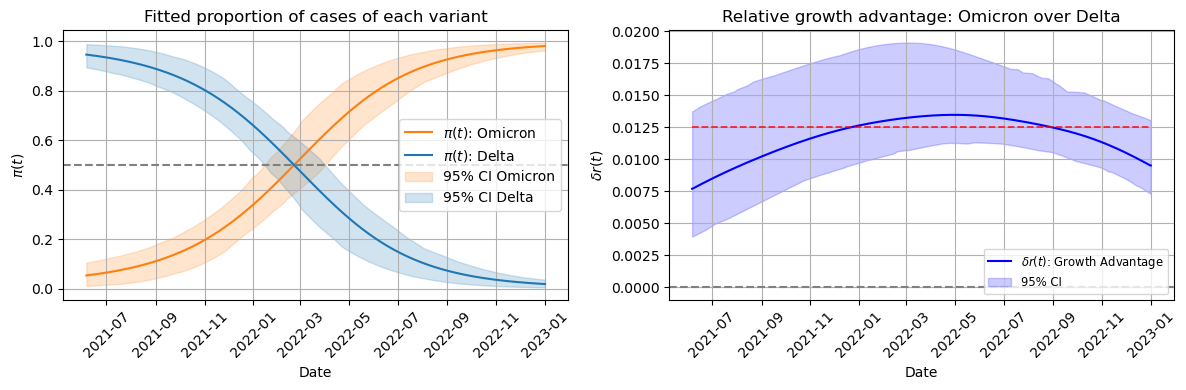

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Fitted proportion plot
axes[0].plot(dates, pi_mean,     label=r"$\pi(t)$: Omicron", color="#ff7f0e")
axes[0].plot(dates, 1 - pi_mean, label=r"$\pi(t)$: Delta",   color="#1f77b4")
axes[0].fill_between(dates, pi_lower, pi_upper,
                     color="#ff7f0e", alpha=0.2, label="95% CI Omicron")
axes[0].fill_between(dates, 1 - pi_lower, 1 - pi_upper,
                     color="#1f77b4", alpha=0.2, label="95% CI Delta")
axes[0].axhline(0.5, linestyle='--', color='grey')
axes[0].set_title("Fitted proportion of cases of each variant")
axes[0].set_ylabel(r"$\pi(t)$")
axes[0].set_xlabel("Date")
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()
axes[0].grid(True)

# Growth advantage plot
axes[1].plot(dates, r_mean, label=r"$\delta r(t)$: Growth Advantage", color="blue")
axes[1].fill_between(dates, r_lower, r_upper,
                     color="blue", alpha=0.2, label="95% CI")
axes[1].axhline(0, linestyle="--", color="grey")
axes[1].hlines(y=0.0125,
               xmin=dates.min(),
               xmax=dates.max(),
               colors="red", linestyles="--", linewidth=1.3, alpha=0.8)
axes[1].set_ylabel(r"$\delta r(t)$")
axes[1].set_xlabel("Date")
axes[1].set_title("Relative growth advantage: Omicron over Delta")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(loc='lower right', fontsize='small')
axes[1].grid(True)

plt.tight_layout()
plt.show()